### Import libraries and configure paths

In [1]:
from pathlib import Path

import pandas as pd
import numpy as np
import networkx as nx
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.max_columns", 20)
pd.set_option("display.width", 160)

sns.set_theme(style="whitegrid")

cwd = Path.cwd().resolve()

if (cwd / "data" / "raw").exists():
    PROJECT_ROOT = cwd
elif (cwd.parent / "data" / "raw").exists():
    PROJECT_ROOT = cwd.parent
else:
    raise FileNotFoundError("Project data folder not found.")

DATA_DIR = PROJECT_ROOT / "data" / "raw"
FIGURE_DIR = PROJECT_ROOT / "outputs" / "figures"
TABLE_DIR = PROJECT_ROOT / "outputs" / "tables"

FIGURE_DIR.mkdir(parents=True, exist_ok=True)
TABLE_DIR.mkdir(parents=True, exist_ok=True)

print("Project root:", PROJECT_ROOT)
print("NetworkX version:", nx.__version__)

Project root: E:\projects\Graph Theory Project\Bitcoin_AML_Graph_Research
NetworkX version: 3.7


### Load the dataset

In [3]:
features = pd.read_csv(
    DATA_DIR / "elliptic_txs_features.csv",
    header=None,
    dtype={0: "string"}
)

num_features = features.shape[1] - 2

features.columns = (
    ["txId", "time_step"]
    + [f"feature_{i}" for i in range(1, num_features + 1)]
)

classes = pd.read_csv(
    DATA_DIR / "elliptic_txs_classes.csv",
    dtype={"txId": "string"}
)

edges = pd.read_csv(
    DATA_DIR / "elliptic_txs_edgelist.csv",
    dtype={"txId1": "string", "txId2": "string"}
)

classes.columns = classes.columns.str.strip()
edges.columns = edges.columns.str.strip()

features["txId"] = features["txId"].str.strip()
classes["txId"] = classes["txId"].str.strip()

edges["txId1"] = edges["txId1"].str.strip()
edges["txId2"] = edges["txId2"].str.strip()

features["time_step"] = features["time_step"].astype(int)
classes["class"] = classes["class"].astype("string").str.strip()

df = features[["txId", "time_step"]].merge(
    classes,
    on="txId",
    how="left",
    validate="one_to_one"
)

class_mapping = {
    "1": "Illicit",
    "2": "Licit",
    "unknown": "Unknown"
}

df["class_name"] = df["class"].map(class_mapping)

print("Transactions:", len(df))
print("Edges:", len(edges))
print("Time steps:", df["time_step"].nunique())

display(df.head())

Transactions: 203769
Edges: 234355
Time steps: 49


,txId,time_step,class,class_name
0,230425980,1,unknown,Unknown
1,5530458,1,unknown,Unknown
2,232022460,1,unknown,Unknown
3,232438397,1,2,Licit
4,230460314,1,unknown,Unknown


### Construct the directed transaction graph

Mathematical representation:
\[
G=(V,E)
\]

Where:
- \(V\) represents Bitcoin transactions.
- \(E\) represents directed transaction-flow connections.

In [4]:
G = nx.DiGraph()

G.add_nodes_from(df["txId"])

G.add_edges_from(
    edges[["txId1", "txId2"]].itertuples(
        index=False,
        name=None
    )
)

node_class = dict(
    zip(df["txId"], df["class_name"])
)

node_time = dict(
    zip(df["txId"], df["time_step"])
)

nx.set_node_attributes(G, node_class, "class_name")
nx.set_node_attributes(G, node_time, "time_step")

print("GRAPH CONSTRUCTION")
print("=" * 50)

print("Graph type:", type(G).__name__)
print("Directed:", G.is_directed())
print("Number of nodes:", G.number_of_nodes())
print("Number of edges:", G.number_of_edges())

assert G.number_of_nodes() == len(df)
assert G.number_of_edges() == len(edges)

print("\nDirected transaction graph created successfully.")

GRAPH CONSTRUCTION
Graph type: DiGraph
Directed: True
Number of nodes: 203769
Number of edges: 234355

Directed transaction graph created successfully.


### Calculate fundamental graph properties

For a directed graph with $n$ nodes and $m$ edges:
$$
\text{Density}(G)=\frac{m}{n(n-1)}
$$

Average total degree:
$$
\bar d=\frac{2m}{n}
$$

In [6]:
n = G.number_of_nodes()
m = G.number_of_edges()

graph_density = nx.density(G)
average_in_degree = m / n
average_out_degree = m / n
average_total_degree = 2 * m / n

isolated_nodes = nx.number_of_isolates(G)

graph_summary = pd.DataFrame({
    "Metric": [
        "Number of Nodes",
        "Number of Directed Edges",
        "Graph Density",
        "Average In-Degree",
        "Average Out-Degree",
        "Average Total Degree",
        "Isolated Nodes"
    ],
    "Value": [
        n,
        m,
        graph_density,
        average_in_degree,
        average_out_degree,
        average_total_degree,
        isolated_nodes
    ]
})

display(graph_summary)

graph_summary.to_csv(
    TABLE_DIR / "03_graph_summary.csv",
    index=False
)

,Metric,Value
0,Number of Nodes,203769.000000
1,Number of Directed Edges,234355.000000
2,Graph Density,0.000006
3,Average In-Degree,1.150101
4,Average Out-Degree,1.150101
5,Average Total Degree,2.300203
6,Isolated Nodes,0.000000


### Calculate in-degree, out-degree, and total degree

For a transaction node $v$:
$$
d(v)=d_{in}(v)+d_{out}(v)
$$

In [7]:
in_degree = dict(G.in_degree())
out_degree = dict(G.out_degree())

graph_features = df.copy()

graph_features["in_degree"] = (
    graph_features["txId"].map(in_degree)
)

graph_features["out_degree"] = (
    graph_features["txId"].map(out_degree)
)

graph_features["total_degree"] = (
    graph_features["in_degree"]
    + graph_features["out_degree"]
)

graph_features["degree_difference"] = (
    graph_features["out_degree"]
    - graph_features["in_degree"]
)

graph_features["degree_ratio"] = (
    (graph_features["out_degree"] + 1)
    / (graph_features["in_degree"] + 1)
)

print("DEGREE STATISTICS")
print("=" * 50)

display(
    graph_features[
        [
            "in_degree",
            "out_degree",
            "total_degree",
            "degree_difference",
            "degree_ratio"
        ]
    ].describe()
)

DEGREE STATISTICS


,in_degree,out_degree,total_degree,degree_difference,degree_ratio
count,203769.000000,203769.000000,203769.000000,203769.000000,203769.000000
mean,1.150101,1.150101,2.300203,0.000000,1.359838
std,3.911132,1.894740,4.328377,4.363385,1.393788
min,0.000000,0.000000,1.000000,-284.000000,0.003509
25%,0.000000,1.000000,1.000000,0.000000,1.000000
50%,1.000000,1.000000,2.000000,0.000000,1.000000
75%,1.000000,1.000000,2.000000,1.000000,2.000000
max,284.000000,472.000000,473.000000,471.000000,236.500000


### Visualize the degree distributions

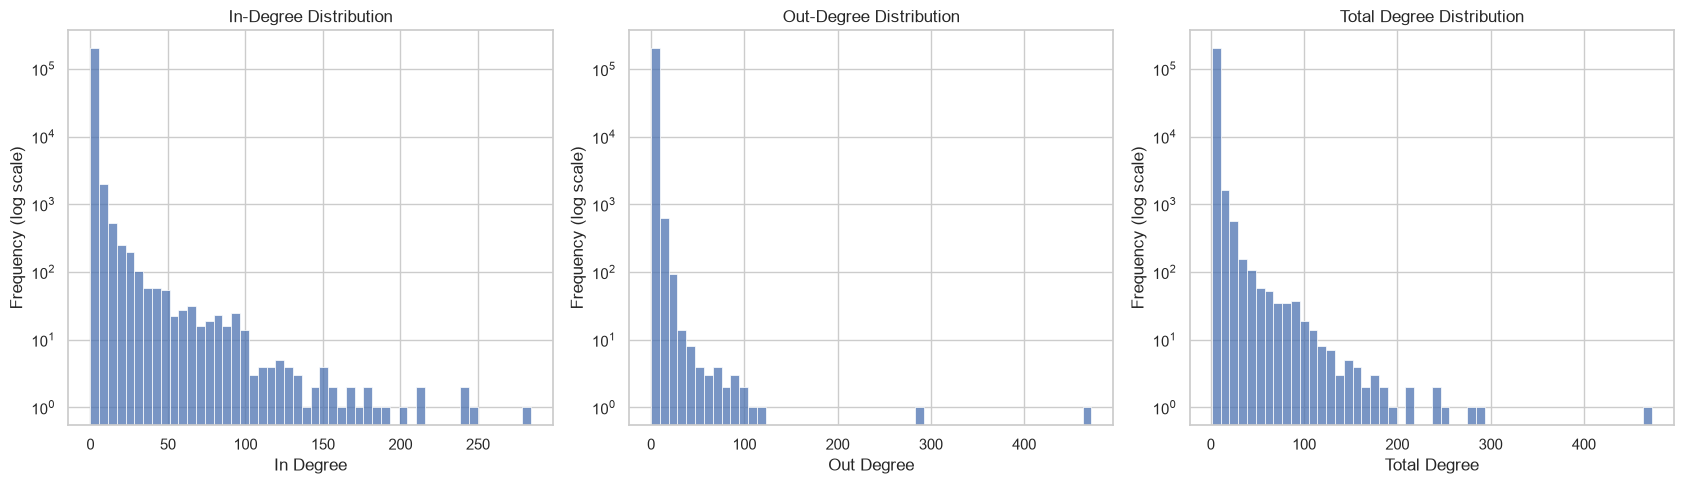

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(17, 5))

degree_columns = [
    ("in_degree", "In-Degree Distribution"),
    ("out_degree", "Out-Degree Distribution"),
    ("total_degree", "Total Degree Distribution")
]

for ax, (column, title) in zip(axes, degree_columns):

    sns.histplot(
        data=graph_features,
        x=column,
        bins=50,
        ax=ax
    )

    ax.set_yscale("log")
    ax.set_title(title)
    ax.set_xlabel(column.replace("_", " ").title())
    ax.set_ylabel("Frequency (log scale)")

plt.tight_layout()

plt.savefig(
    FIGURE_DIR / "05_degree_distributions.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

### Compare degrees between illicit and licit transactions

In [9]:
labeled_graph = graph_features[
    graph_features["class_name"].isin(
        ["Illicit", "Licit"]
    )
].copy()

degree_comparison = (
    labeled_graph.groupby("class_name")[
        ["in_degree", "out_degree", "total_degree"]
    ]
    .agg(["mean", "median", "std", "max"])
)

print("DEGREE COMPARISON BY TRANSACTION CLASS")

display(degree_comparison)

degree_comparison.to_csv(
    TABLE_DIR / "04_degree_class_comparison.csv"
)

DEGREE COMPARISON BY TRANSACTION CLASS


in_degree                       out_degree                       total_degree                      
                mean median       std  max       mean median       std  max         mean median       std  max
class_name                                                                                                    
Illicit     1.269967    1.0  7.215218  177   0.741694    1.0  0.571620    3     2.011661    1.0  7.177521  177
Licit       1.909398    1.0  7.122538  284   1.185821    1.0  3.246769  472     3.095219    2.0  7.782942  473

### Visualize class-wise degree comparison

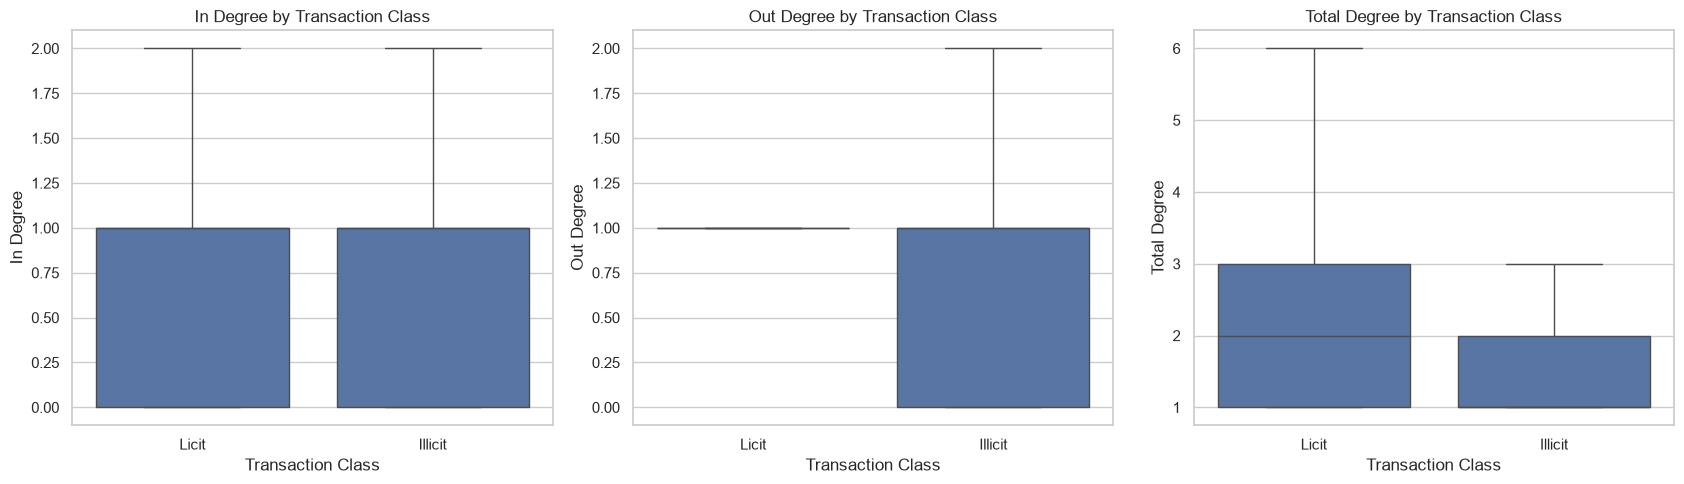

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(17, 5))

degree_metrics = [
    "in_degree",
    "out_degree",
    "total_degree"
]

for ax, metric in zip(axes, degree_metrics):

    sns.boxplot(
        data=labeled_graph,
        x="class_name",
        y=metric,
        order=["Licit", "Illicit"],
        showfliers=False,
        ax=ax
    )

    ax.set_title(
        metric.replace("_", " ").title()
        + " by Transaction Class"
    )

    ax.set_xlabel("Transaction Class")
    ax.set_ylabel(metric.replace("_", " ").title())

plt.tight_layout()

plt.savefig(
    FIGURE_DIR / "06_degree_comparison_by_class.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

### Analyze connected components

A weakly connected component is a group of nodes connected when edge directions are ignored.

A strongly connected component is a group where every node can reach every other node through directed paths.

In [11]:
weak_components = list(
    nx.weakly_connected_components(G)
)

strong_components = list(
    nx.strongly_connected_components(G)
)

weak_sizes = sorted(
    [len(component) for component in weak_components],
    reverse=True
)

strong_sizes = sorted(
    [len(component) for component in strong_components],
    reverse=True
)

print("CONNECTED COMPONENT ANALYSIS")
print("=" * 50)

print("Weakly connected components:", len(weak_components))
print("Strongly connected components:", len(strong_components))

print("Largest weak component:", weak_sizes[0])
print("Largest strong component:", strong_sizes[0])

print("Top 10 weak component sizes:", weak_sizes[:10])
print("Top 10 strong component sizes:", strong_sizes[:10])

CONNECTED COMPONENT ANALYSIS
Weakly connected components: 49
Strongly connected components: 203769
Largest weak component: 7880
Largest strong component: 1
Top 10 weak component sizes: [7880, 7140, 6803, 6727, 6621, 6393, 6048, 5894, 5693, 5598]
Top 10 strong component sizes: [1, 1, 1, 1, 1, 1, 1, 1, 1, 1]


### Assign weak-component features

In [12]:
component_id = {}
component_size = {}

for idx, component in enumerate(weak_components):

    size = len(component)

    for node in component:
        component_id[node] = idx
        component_size[node] = size

graph_features["component_id"] = (
    graph_features["txId"].map(component_id)
)

graph_features["component_size"] = (
    graph_features["txId"].map(component_size)
)

print("WEAK COMPONENT SIZE STATISTICS")

display(
    graph_features["component_size"].describe()
)

print("\nLargest weakly connected components:")

display(
    pd.DataFrame({
        "component_size": weak_sizes[:15]
    })
)

WEAK COMPONENT SIZE STATISTICS


count    203769.000000
mean       4755.924537
std        1544.332842
min        1089.000000
25%        3519.000000
50%        4544.000000
75%        5894.000000
max        7880.000000
Name: component_size, dtype: float64


Largest weakly connected components:


,component_size
0,7880
1,7140
2,6803
3,6727
4,6621
5,6393
6,6048
7,5894
8,5693
9,5598


### Visualize connected component sizes

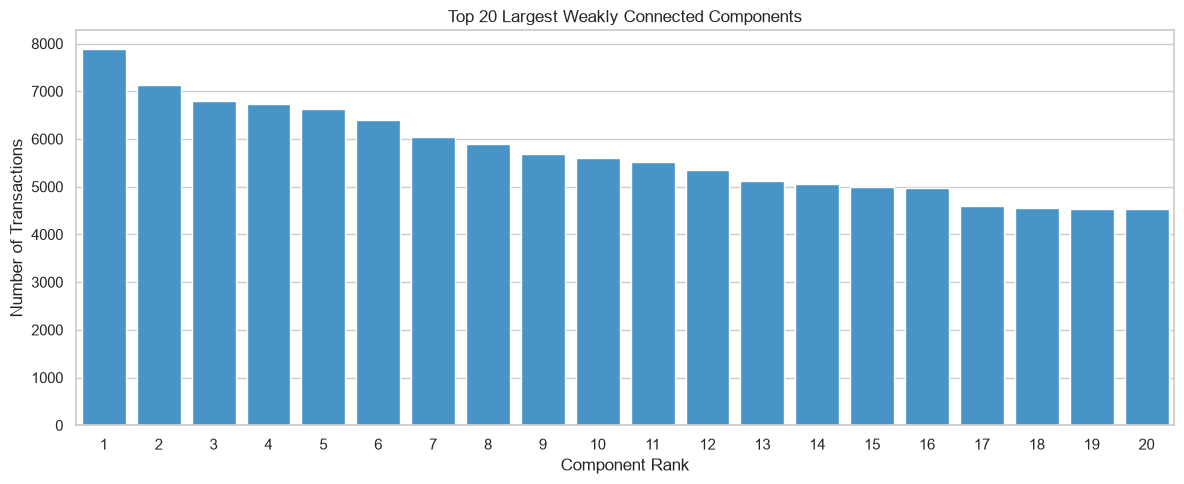

In [13]:
top_components = weak_sizes[:20]

plt.figure(figsize=(12, 5))

sns.barplot(
    x=list(range(1, len(top_components) + 1)),
    y=top_components,
    color="#3498db"
)

plt.title("Top 20 Largest Weakly Connected Components")
plt.xlabel("Component Rank")
plt.ylabel("Number of Transactions")

plt.tight_layout()

plt.savefig(
    FIGURE_DIR / "07_largest_components.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

### Calculate PageRank centrality

PageRank measures the structural importance of nodes based on incoming connections and the importance of their neighbors.
$$
PR(v)=\frac{1-d}{N}+d\sum_{u\rightarrow v}\frac{PR(u)}{L(u)}
$$

Here, $d$ is the damping factor and $L(u)$ is the out-degree of node $u$. Dangling nodes are handled through redistribution in the standard algorithm.

Because all edges are within individual time steps, PageRank can be computed separately for each time-step graph. This is equivalent to using the graph structure available in that time step without connecting different periods.

In [14]:
pagerank_scores = {}

time_steps = sorted(df["time_step"].unique())

for step in time_steps:

    step_nodes = df.loc[
        df["time_step"] == step,
        "txId"
    ].tolist()

    G_step = G.subgraph(step_nodes)

    scores = nx.pagerank(
        G_step,
        alpha=0.85,
        max_iter=200,
        tol=1e-6
    )

    pagerank_scores.update(scores)

    print(
        f"Time step {step:02d}: "
        f"{G_step.number_of_nodes():,} nodes, "
        f"{G_step.number_of_edges():,} edges"
    )

graph_features["pagerank"] = (
    graph_features["txId"].map(pagerank_scores)
)

print("\nPageRank calculation completed.")

display(
    graph_features["pagerank"].describe()
)

Time step 01: 7,880 nodes, 9,164 edges
Time step 02: 4,544 nodes, 5,241 edges
Time step 03: 6,621 nodes, 8,316 edges
Time step 04: 5,693 nodes, 8,180 edges
Time step 05: 6,803 nodes, 8,623 edges
Time step 06: 4,328 nodes, 5,242 edges
Time step 07: 6,048 nodes, 7,253 edges
Time step 08: 4,457 nodes, 5,186 edges
Time step 09: 4,996 nodes, 5,939 edges
Time step 10: 6,727 nodes, 8,588 edges
Time step 11: 4,296 nodes, 4,656 edges
Time step 12: 2,047 nodes, 2,213 edges
Time step 13: 4,528 nodes, 4,827 edges
Time step 14: 2,022 nodes, 2,078 edges
Time step 15: 3,639 nodes, 3,823 edges
Time step 16: 2,975 nodes, 3,120 edges
Time step 17: 3,385 nodes, 3,650 edges
Time step 18: 1,976 nodes, 2,115 edges
Time step 19: 3,506 nodes, 3,838 edges
Time step 20: 4,291 nodes, 4,755 edges
Time step 21: 3,537 nodes, 3,959 edges
Time step 22: 5,894 nodes, 7,014 edges
Time step 23: 4,165 nodes, 4,584 edges
Time step 24: 4,592 nodes, 5,124 edges
Time step 25: 2,314 nodes, 2,619 edges
Time step 26: 2,523 nodes

count    203769.000000
mean          0.000240
std           0.000463
min           0.000036
25%           0.000086
50%           0.000146
75%           0.000264
max           0.026554
Name: pagerank, dtype: float64

### Normalize PageRank for graph-size comparison

Because PageRank scores sum to one within each time-step graph, their scale depends on the number of nodes in that graph.

We will also calculate:
$$
PR_{\text{scaled}}(v)=|V_t|PR(v)
$$

where $|V_t|$ is the number of nodes in time step $t$.

In [15]:
step_sizes = (
    df.groupby("time_step")
    .size()
    .to_dict()
)

graph_features["time_step_size"] = (
    graph_features["time_step"].map(step_sizes)
)

graph_features["pagerank_scaled"] = (
    graph_features["pagerank"]
    * graph_features["time_step_size"]
)

print("SCALED PAGERANK STATISTICS")

display(
    graph_features["pagerank_scaled"].describe()
)

SCALED PAGERANK STATISTICS


count    203769.000000
mean          1.000000
std           1.796467
min           0.239865
25%           0.396412
50%           0.647622
75%           1.150155
max          99.599367
Name: pagerank_scaled, dtype: float64

### Compare PageRank between classes

pagerank                               pagerank_scaled                               
                mean    median       std       max            mean    median       std        max
class_name                                                                                       
Illicit     0.000222  0.000134  0.000746  0.025081        0.843513  0.535100  2.390044  66.165895
Licit       0.000272  0.000119  0.000777  0.026554        1.154378  0.481148  3.092679  99.599367

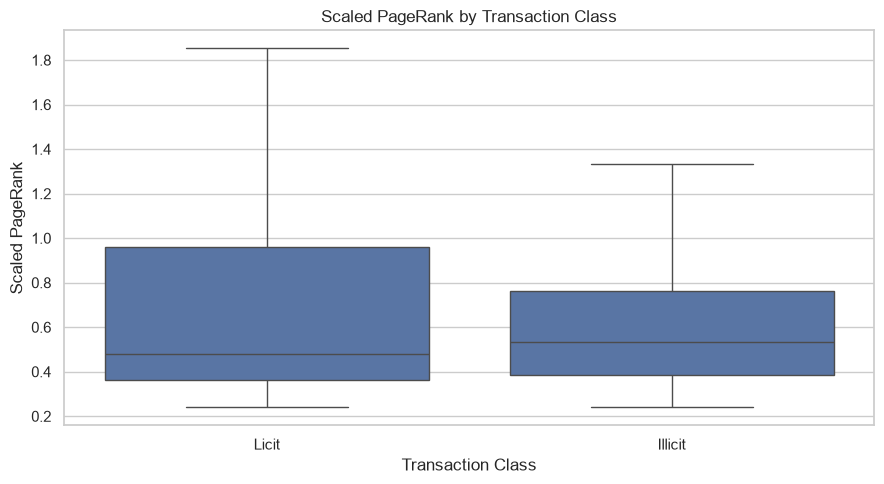

In [16]:
labeled_graph = graph_features[
    graph_features["class_name"].isin(
        ["Illicit", "Licit"]
    )
].copy()

pagerank_comparison = (
    labeled_graph.groupby("class_name")[
        ["pagerank", "pagerank_scaled"]
    ]
    .agg(["mean", "median", "std", "max"])
)

display(pagerank_comparison)

pagerank_comparison.to_csv(
    TABLE_DIR / "05_pagerank_class_comparison.csv"
)

plt.figure(figsize=(9, 5))

sns.boxplot(
    data=labeled_graph,
    x="class_name",
    y="pagerank_scaled",
    order=["Licit", "Illicit"],
    showfliers=False
)

plt.title("Scaled PageRank by Transaction Class")
plt.xlabel("Transaction Class")
plt.ylabel("Scaled PageRank")

plt.tight_layout()

plt.savefig(
    FIGURE_DIR / "08_pagerank_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

### Analyze graph structure over time

In [17]:
temporal_graph_stats = []

for step in time_steps:

    step_nodes = df.loc[
        df["time_step"] == step,
        "txId"
    ].tolist()

    G_step = G.subgraph(step_nodes)

    step_n = G_step.number_of_nodes()
    step_m = G_step.number_of_edges()

    temporal_graph_stats.append({
        "time_step": step,
        "nodes": step_n,
        "edges": step_m,
        "density": nx.density(G_step),
        "average_degree": (
            2 * step_m / step_n
            if step_n > 0 else 0
        ),
        "isolated_nodes": nx.number_of_isolates(G_step)
    })

temporal_graph_df = pd.DataFrame(
    temporal_graph_stats
)

display(temporal_graph_df.head(10))

temporal_graph_df.to_csv(
    TABLE_DIR / "06_temporal_graph_statistics.csv",
    index=False
)

,time_step,nodes,edges,density,average_degree,isolated_nodes
0,1,7880,9164,0.000148,2.325888,0
1,2,4544,5241,0.000254,2.306778,0
2,3,6621,8316,0.000190,2.512007,0
3,4,5693,8180,0.000252,2.873705,0
4,5,6803,8623,0.000186,2.535058,0
5,6,4328,5242,0.000280,2.422366,0
6,7,6048,7253,0.000198,2.398479,0
7,8,4457,5186,0.000261,2.327126,0
8,9,4996,5939,0.000238,2.377502,0
9,10,6727,8588,0.000190,2.553293,0


### Visualize network evolution

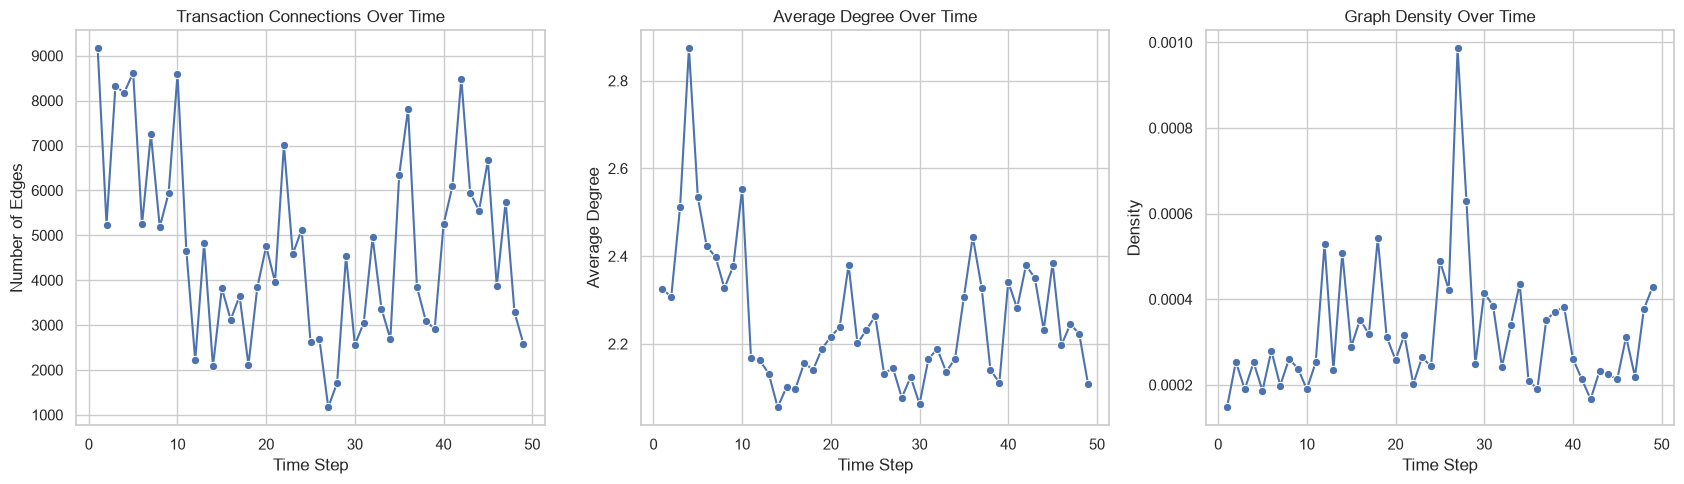

In [18]:
fig, axes = plt.subplots(1, 3, figsize=(17, 5))

sns.lineplot(
    data=temporal_graph_df,
    x="time_step",
    y="edges",
    marker="o",
    ax=axes[0]
)

axes[0].set_title("Transaction Connections Over Time")
axes[0].set_xlabel("Time Step")
axes[0].set_ylabel("Number of Edges")

sns.lineplot(
    data=temporal_graph_df,
    x="time_step",
    y="average_degree",
    marker="o",
    ax=axes[1]
)

axes[1].set_title("Average Degree Over Time")
axes[1].set_xlabel("Time Step")
axes[1].set_ylabel("Average Degree")

sns.lineplot(
    data=temporal_graph_df,
    x="time_step",
    y="density",
    marker="o",
    ax=axes[2]
)

axes[2].set_title("Graph Density Over Time")
axes[2].set_xlabel("Time Step")
axes[2].set_ylabel("Density")

plt.tight_layout()

plt.savefig(
    FIGURE_DIR / "09_graph_evolution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

### Create a real transaction-network visualization

Selected time step: 32
Visualization nodes: 120
Visualization edges: 122

Class distribution:
Unknown    95
Licit      24
Illicit     1
Name: count, dtype: int64


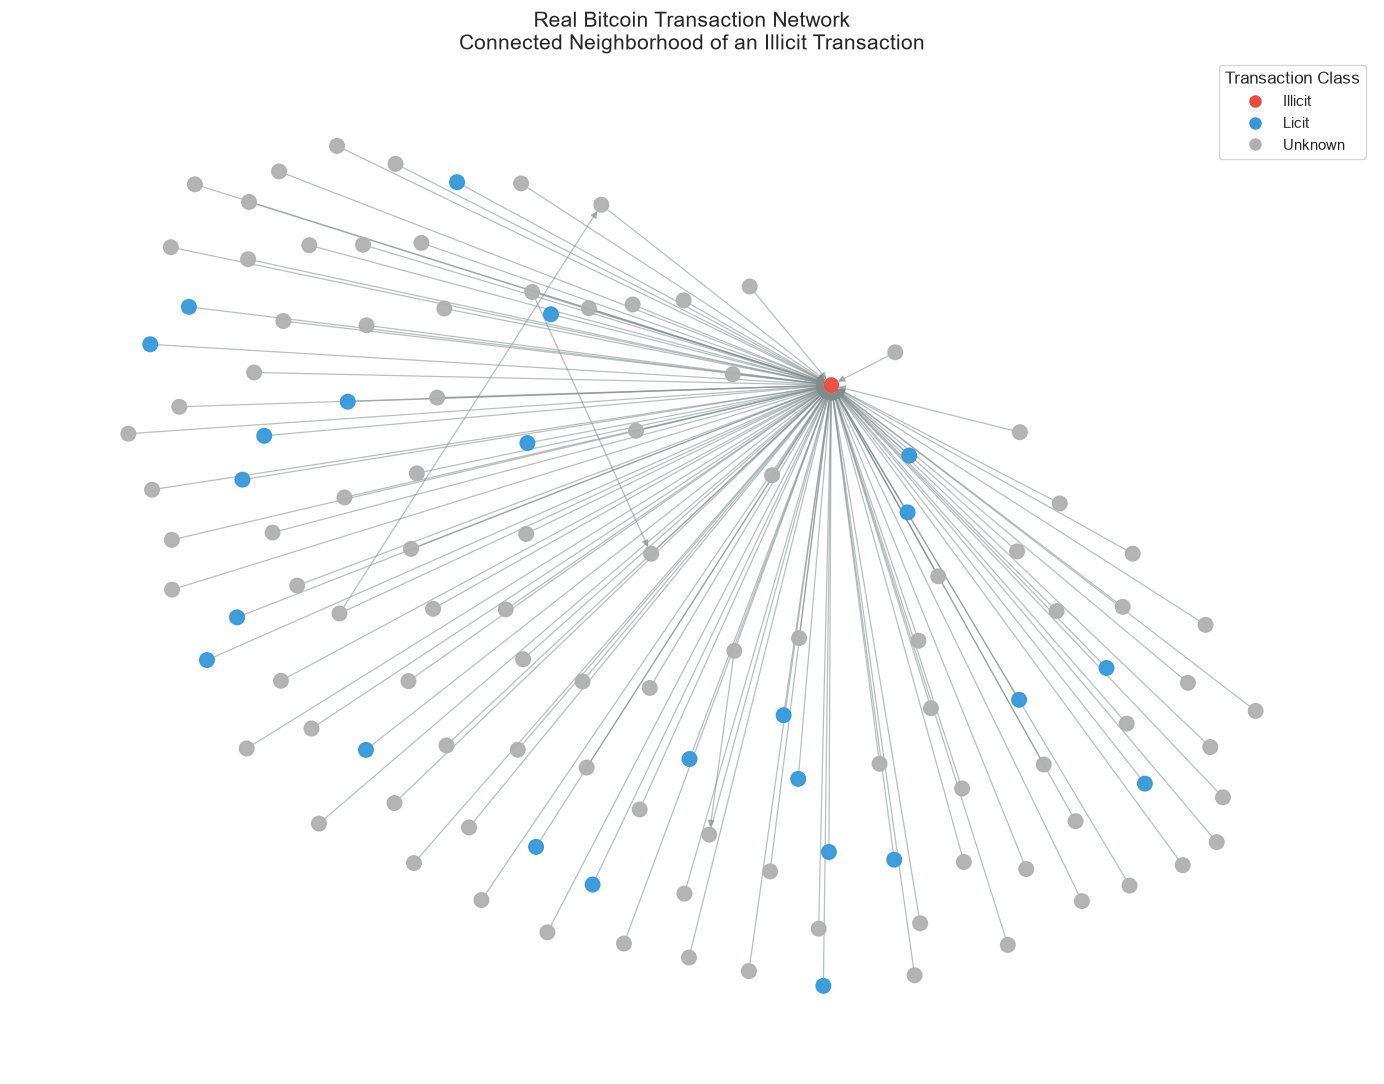

In [24]:
from collections import deque
from matplotlib.lines import Line2D

MAX_NODES = 120
MIN_NODES = 40

# Find the largest weakly connected component containing illicit nodes.
eligible_components = [
    component
    for component in weak_components
    if len(component) >= MIN_NODES
    and len(component & illicit_nodes) > 0
]

selected_component = max(
    eligible_components,
    key=lambda c: (
        len(c & illicit_nodes),
        len(c)
    )
)

G_component = G.subgraph(selected_component)

# Start from an illicit node with the highest local connectivity.
seed = max(
    selected_component & illicit_nodes,
    key=lambda node: (
        G_component.degree(node),
        str(node)
    )
)

# Breadth-first traversal to obtain a connected real subgraph.
selected_nodes = []
visited = {seed}
queue = deque([seed])

while queue and len(selected_nodes) < MAX_NODES:

    node = queue.popleft()
    selected_nodes.append(node)

    neighbors = sorted(
        G_component.predecessors(node)
    ) + sorted(
        G_component.successors(node)
    )

    for neighbor in neighbors:
        if neighbor not in visited:
            visited.add(neighbor)
            queue.append(neighbor)

G_vis = G_component.subgraph(selected_nodes).copy()

color_map = {
    "Illicit": "#e74c3c",
    "Licit": "#3498db",
    "Unknown": "#b0b0b0"
}

node_colors = [
    color_map[G_vis.nodes[node]["class_name"]]
    for node in G_vis.nodes()
]

print("Selected time step:", G_vis.nodes[seed]["time_step"])
print("Visualization nodes:", G_vis.number_of_nodes())
print("Visualization edges:", G_vis.number_of_edges())

class_counts_vis = pd.Series(
    [
        G_vis.nodes[node]["class_name"]
        for node in G_vis.nodes()
    ]
).value_counts()

print("\nClass distribution:")
print(class_counts_vis)

plt.figure(figsize=(14, 11))

pos = nx.spring_layout(
    G_vis,
    seed=42,
    iterations=150,
    k=0.45
)

nx.draw_networkx_nodes(
    G_vis,
    pos,
    node_color=node_colors,
    node_size=110,
    alpha=0.95
)

nx.draw_networkx_edges(
    G_vis,
    pos,
    arrows=True,
    arrowsize=10,
    node_size=110,
    width=0.9,
    alpha=0.55,
    edge_color="#7f8c8d"
)

legend_elements = [
    Line2D(
        [0], [0],
        marker="o",
        color="w",
        markerfacecolor=color,
        markersize=10,
        label=label
    )
    for label, color in color_map.items()
]

plt.legend(
    handles=legend_elements,
    title="Transaction Class",
    loc="upper right"
)

plt.title(
    "Real Bitcoin Transaction Network\n"
    "Connected Neighborhood of an Illicit Transaction",
    fontsize=15
)

plt.axis("off")
plt.tight_layout()

plt.savefig(
    FIGURE_DIR / "10_transaction_network.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

### Visualize the degree distribution on logarithmic scales

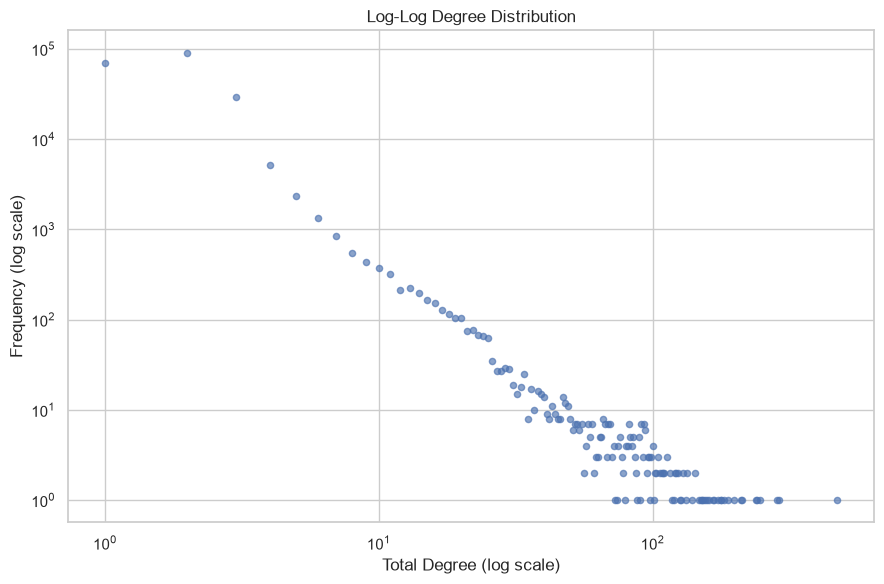

In [20]:
degree_frequency = (
    graph_features["total_degree"]
    .value_counts()
    .sort_index()
)

degree_frequency = degree_frequency[
    degree_frequency.index > 0
]

plt.figure(figsize=(9, 6))

plt.scatter(
    degree_frequency.index,
    degree_frequency.values,
    alpha=0.65,
    s=20
)

plt.xscale("log")
plt.yscale("log")

plt.title("Log-Log Degree Distribution")
plt.xlabel("Total Degree (log scale)")
plt.ylabel("Frequency (log scale)")

plt.tight_layout()

plt.savefig(
    FIGURE_DIR / "11_loglog_degree_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

### Compare graph features statistically

In [21]:
from scipy.stats import mannwhitneyu

metrics = [
    "in_degree",
    "out_degree",
    "total_degree",
    "degree_ratio",
    "component_size",
    "pagerank_scaled"
]

statistical_results = []

illicit_data = graph_features[
    graph_features["class_name"] == "Illicit"
]

licit_data = graph_features[
    graph_features["class_name"] == "Licit"
]

for metric in metrics:

    illicit_values = illicit_data[metric].dropna()
    licit_values = licit_data[metric].dropna()

    statistic, p_value = mannwhitneyu(
        illicit_values,
        licit_values,
        alternative="two-sided"
    )

    statistical_results.append({
        "feature": metric,
        "illicit_median": illicit_values.median(),
        "licit_median": licit_values.median(),
        "U_statistic": statistic,
        "p_value": p_value
    })

statistical_df = pd.DataFrame(
    statistical_results
)

display(statistical_df)

statistical_df.to_csv(
    TABLE_DIR / "07_graph_feature_statistical_tests.csv",
    index=False
)

,feature,illicit_median,licit_median,U_statistic,p_value
0,in_degree,1.0000,1.000000,90293567.5,5.552428e-11
1,out_degree,1.0000,1.000000,77335837.5,1.441678e-118
2,total_degree,1.0000,2.000000,71696129.5,6.844822e-188
3,degree_ratio,1.0000,1.000000,88301146.0,1.999251e-17
4,component_size,4296.0000,4975.000000,71864381.5,6.427535e-166
5,pagerank_scaled,0.5351,0.481148,96477101.0,2.506438e-01


### Save graph-theoretical features

In [22]:
graph_feature_columns = [
    "txId",
    "time_step",
    "class",
    "class_name",
    "in_degree",
    "out_degree",
    "total_degree",
    "degree_difference",
    "degree_ratio",
    "component_size",
    "pagerank",
    "pagerank_scaled"
]

graph_features_export = graph_features[
    graph_feature_columns
].copy()

output_path = (
    TABLE_DIR / "08_graph_features.csv"
)

graph_features_export.to_csv(
    output_path,
    index=False
)

print("Graph features saved:")
print(output_path)

print("\nExport shape:", graph_features_export.shape)

display(graph_features_export.head())

Graph features saved:
E:\projects\Graph Theory Project\Bitcoin_AML_Graph_Research\outputs\tables\08_graph_features.csv

Export shape: (203769, 12)


,txId,time_step,class,class_name,in_degree,out_degree,total_degree,degree_difference,degree_ratio,component_size,pagerank,pagerank_scaled
0,230425980,1,unknown,Unknown,1,1,2,0,1.000000,7880,0.000105,0.829387
1,5530458,1,unknown,Unknown,1,1,2,0,1.000000,7880,0.000130,1.026302
2,232022460,1,unknown,Unknown,1,2,3,1,1.500000,7880,0.000130,1.022974
3,232438397,1,2,Licit,160,1,161,-159,0.012422,7880,0.007200,56.734084
4,230460314,1,unknown,Unknown,2,8,10,6,3.000000,7880,0.000055,0.430029


### Final notebook validation

In [23]:
print("=" * 60)
print("NOTEBOOK 02 - FINAL VALIDATION")
print("=" * 60)

required_columns = [
    "in_degree",
    "out_degree",
    "total_degree",
    "degree_difference",
    "degree_ratio",
    "component_size",
    "pagerank",
    "pagerank_scaled"
]

checks = {
    "Correct number of nodes": (
        G.number_of_nodes() == 203769
    ),
    "Correct number of edges": (
        G.number_of_edges() == 234355
    ),
    "All graph features generated": all(
        col in graph_features.columns
        for col in required_columns
    ),
    "No missing graph feature values": (
        graph_features[required_columns]
        .isna()
        .sum()
        .sum() == 0
    ),
    "Degree sum matches graph edges": (
        graph_features["in_degree"].sum() == m
        and graph_features["out_degree"].sum() == m
    ),
    "49 temporal graphs analyzed": (
        len(temporal_graph_df) == 49
    ),
    "Graph feature CSV saved": (
        output_path.exists()
    )
}

for name, passed in checks.items():
    print(
        f"{'PASS' if passed else 'CHECK'}: {name}"
    )

print("\nGenerated figures:")

for file in sorted(FIGURE_DIR.glob("*.png")):
    print("-", file.name)

print("\nGenerated tables:")

for file in sorted(TABLE_DIR.glob("*.csv")):
    print("-", file.name)

if all(checks.values()):
    print("\nNotebook 02 completed successfully!")
else:
    print("\nReview flagged checks before continuing.")

NOTEBOOK 02 - FINAL VALIDATION
PASS: Correct number of nodes
PASS: Correct number of edges
PASS: All graph features generated
PASS: No missing graph feature values
PASS: Degree sum matches graph edges
PASS: 49 temporal graphs analyzed
PASS: Graph feature CSV saved

Generated figures:
- 01_class_distribution.png
- 02_transactions_over_time.png
- 03_class_distribution_over_time.png
- 04_illicit_percentage_over_time.png
- 05_degree_distributions.png
- 06_degree_comparison_by_class.png
- 07_largest_components.png
- 08_pagerank_comparison.png
- 09_graph_evolution.png
- 10_transaction_network.png
- 11_loglog_degree_distribution.png

Generated tables:
- 01_dataset_summary.csv
- 02_temporal_class_statistics.csv
- 03_graph_summary.csv
- 04_degree_class_comparison.csv
- 05_pagerank_class_comparison.csv
- 06_temporal_graph_statistics.csv
- 07_graph_feature_statistical_tests.csv
- 08_graph_features.csv

Notebook 02 completed successfully!
